# 02 — Baseline TF-IDF + régression logistique

**DATA4001 · Protocole A uniquement · seed 42**

Deux expériences indépendantes : `informative` et `humanitarian`. Le train est
dédupliqué par tweet via `get_split(..., text_only=True)` ; dev et test sont conservés.
Le TF-IDF est appris sur train uniquement. Le meilleur `C` est choisi sur le F1 macro
**dev**, puis le modèle déjà entraîné est évalué **une seule fois sur test**.
Aucun réentraînement sur train + dev, aucun protocole B.

Toutes les métriques et tous les exports de prédictions passent par `src/evaluate.py`.
Les scores affichés sont sur [0, 1]. Les sorties de ce notebook proviennent de son
exécution réelle ; aucune valeur de performance n'est saisie à la main.

## 1. Environnement et configuration

Prérequis : les six CSV nettoyés dans `splits/`, le dépôt et ses dépendances
(`python -m pip install -r requirements.txt`). Choisir le kernel de `.venv` et
**Restart Kernel / Run All**. Le notebook fonctionne depuis la racine ou `notebooks/`.
Sur Colab, placer/cloner le dépôt sur le Drive avant l'exécution et renseigner
`REPO_ROOT_OVERRIDE` dans la cellule suivante ; les chemins sont regroupés ici.


In [1]:
from pathlib import Path
import os
import sys

# Sur Colab, exemple après montage du Drive : Path('/content/drive/MyDrive/DATA4001')
REPO_ROOT_OVERRIDE = None
if REPO_ROOT_OVERRIDE is not None:
    REPO_ROOT = Path(REPO_ROOT_OVERRIDE).expanduser().resolve()
else:
    REPO_ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
                      if (p / 'README.md').is_file() and (p / 'src/data.py').is_file()), None)
if REPO_ROOT is None or not (REPO_ROOT / 'src/evaluate.py').is_file():
    raise RuntimeError('Renseigner REPO_ROOT_OVERRIDE avec la racine du dépôt.')
os.chdir(REPO_ROOT)
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

TABLE_DIR = REPO_ROOT / 'results/tables'
FIGURE_DIR = REPO_ROOT / 'figures'
for folder in (TABLE_DIR, FIGURE_DIR):
    folder.mkdir(parents=True, exist_ok=True)
print('Racine :', REPO_ROOT.name)
print('Python :', sys.version.split()[0])


Racine : Applied_Predictive
Python : 3.11.2


In [2]:
import hashlib
import json
import platform
import random
import textwrap
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)

import matplotlib
matplotlib.use("module://matplotlib_inline.backend_inline")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from sklearn.exceptions import ConvergenceWarning
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from threadpoolctl import threadpool_limits

from src.data import LABELS, SEED, get_split
from src.evaluate import compute_metrics, evaluate_file, write_predictions

assert SEED == 42
random.seed(SEED)
np.random.seed(SEED)
C_VALUES = (0.01, 0.1, 1.0, 10.0, 100.0)
TASKS = ('informative', 'humanitarian')
N_BOOTSTRAP = 1000
# Même configuration pour tous les C et les deux tâches ; arrêt si non-convergence.
LR_CONFIG = dict(class_weight='balanced', solver='lbfgs', penalty='l2',
                 max_iter=2000, tol=1e-4, random_state=SEED)
VERSIONS = dict(python=platform.python_version(), numpy=np.__version__,
                pandas=pd.__version__, sklearn=sklearn.__version__,
                matplotlib=matplotlib.__version__)
print('Seed :', SEED, '| Grille C fixée :', C_VALUES)
print('Versions :', VERSIONS)


Seed : 42 | Grille C fixée : (0.01, 0.1, 1.0, 10.0, 100.0)
Versions : {'python': '3.11.2', 'numpy': '2.4.6', 'pandas': '3.0.6', 'sklearn': '1.9.1', 'matplotlib': '3.11.2'}


## 2. Chargement des deux tâches

Les labels et l'ordre de référence des classes viennent de `src/data.py`.
Aucune normalisation supplémentaire du texte : le vectoriseur applique ses défauts
scikit-learn (minuscules, tokenisation standard, IDF lissée, norme L2), avec
`ngram_range=(1, 2)`, sans stopwords ni limite de vocabulaire. Les CSV restent intacts.
Le split test est chargé par l'API commune mais ne sera ni vectorisé ni prédit avant
le verrouillage des deux modèles sur dev.


In [3]:
splits_by_task = {task: get_split(task, "A", "official", text_only=True) for task in TASKS}
size_rows = []
for task, splits in splits_by_task.items():
    for name, frame in splits.items():
        assert not frame['tweet_id'].duplicated().any(), (task, name)
        size_rows.append(dict(task=task, split=name, rows=len(frame),
                              distinct_tweets=frame['tweet_id'].nunique()))
display(pd.DataFrame(size_rows))
# Empreintes utilisées dans le manifeste et vérifiées en fin de notebook.
protected_files = [*sorted((REPO_ROOT / 'splits').glob('*.csv')),
                   *sorted((REPO_ROOT / 'src').glob('*.py'))]
input_hashes = {str(path.relative_to(REPO_ROOT)): hashlib.sha256(path.read_bytes()).hexdigest()
                for path in protected_files}
selected = {}
validation_metrics = {}


,task,split,rows,distinct_tweets
0,informative,train,8293,8293
1,informative,dev,1573,1573
2,informative,test,1534,1534
3,humanitarian,train,5263,5263
4,humanitarian,dev,998,998
5,humanitarian,test,955,955


## 3. Sélection sur dev uniquement

La grille couvre cinq ordres de grandeur de régularisation. Plus `C` est petit,
plus la régularisation L2 est forte. Une seule représentation TF-IDF par tâche,
apprise sur train, est utilisée pour tous les candidats. Chaque régression est
entraînée sur train avec `class_weight="balanced"` ; dev sert uniquement au classement.
En cas d'égalité exacte de F1 macro, le premier candidat (plus petit `C`) est conservé.
Les candidats doivent converger ; une alerte de convergence interrompt l'exécution.

`compute_metrics` fournit aussi les métriques dev et les IC avec les conventions
communes ; seul son champ `f1_macro` détermine la sélection. Il n'y a aucun appel
à une fonction métrique réécrite dans ce notebook.


In [4]:
def select_on_dev(task):
    # Le test ne fait pas partie des arguments ou matrices utilisés ici.
    train = splits_by_task[task]['train']
    dev = splits_by_task[task]['dev']
    vectorizer = TfidfVectorizer(ngram_range=(1, 2))
    x_train = vectorizer.fit_transform(train['tweet_text'])
    x_dev = vectorizer.transform(dev['tweet_text'])
    rows, full_metrics = [], []
    best_model, best_score, best_c = None, -np.inf, None
    for c in C_VALUES:
        candidate = LogisticRegression(C=c, **LR_CONFIG)
        with warnings.catch_warnings(), threadpool_limits(limits=1):
            warnings.simplefilter('error', ConvergenceWarning)
            candidate.fit(x_train, train['label'])
            dev_pred = candidate.predict(x_dev)
        scores = compute_metrics(dev['label'], dev_pred, task,
                                 n_bootstrap=N_BOOTSTRAP, seed=SEED)
        full_metrics.append(dict(C=c, **scores))
        rows.append(dict(task=task, C=c, f1_macro=scores['f1_macro'],
                         f1_weighted=scores['f1_weighted'], accuracy=scores['accuracy'],
                         iterations=int(candidate.n_iter_.max())))
        print(f'{task}: C={c:g}, dev F1 macro={scores["f1_macro"]:.6f}', flush=True)
        if scores['f1_macro'] > best_score:
            best_score, best_model, best_c = scores['f1_macro'], candidate, c
    table = pd.DataFrame(rows)
    table['selected'] = table['C'].eq(best_c)
    table.to_csv(TABLE_DIR / f'{task}_tfidf_A_validation.csv', index=False)
    validation_metrics[task] = full_metrics
    selected[task] = dict(vectorizer=vectorizer, model=best_model, C=best_c,
                          dev_f1_macro=best_score, vocabulary_size=len(vectorizer.vocabulary_),
                          train_rows=len(train), dev_rows=len(dev))
    display(table)
    print(f'Modèle retenu : C={best_c:g} ; vocabulaire={len(vectorizer.vocabulary_):,}')
    return table


## 4. Tâche informative — apprentissage et choix de C


In [5]:
informative_validation = select_on_dev("informative")


informative: C=0.01, dev F1 macro=0.730140


informative: C=0.1, dev F1 macro=0.748760


informative: C=1, dev F1 macro=0.770613


informative: C=10, dev F1 macro=0.762877


informative: C=100, dev F1 macro=0.762961


,task,C,f1_macro,f1_weighted,accuracy,iterations,selected
0,informative,0.01,0.730140,0.767822,0.774952,3,False
1,informative,0.10,0.748760,0.783458,0.789574,7,False
2,informative,1.00,0.770613,0.804941,0.814367,11,True
3,informative,10.00,0.762877,0.800740,0.814367,30,False
4,informative,100.00,0.762961,0.801481,0.816275,18,False


Modèle retenu : C=1 ; vocabulaire=109,673


## 5. Tâche humanitarian — apprentissage et choix de C


In [6]:
humanitarian_validation = select_on_dev("humanitarian")


humanitarian: C=0.01, dev F1 macro=0.508064


humanitarian: C=0.1, dev F1 macro=0.508836


humanitarian: C=1, dev F1 macro=0.555316


humanitarian: C=10, dev F1 macro=0.606684


humanitarian: C=100, dev F1 macro=0.622650


,task,C,f1_macro,f1_weighted,accuracy,iterations,selected
0,humanitarian,0.01,0.508064,0.637122,0.617234,6,False
1,humanitarian,0.10,0.508836,0.652180,0.634269,17,False
2,humanitarian,1.00,0.555316,0.691109,0.680361,54,False
3,humanitarian,10.00,0.606684,0.738731,0.732465,88,False
4,humanitarian,100.00,0.622650,0.747273,0.742485,96,True


Modèle retenu : C=100 ; vocabulaire=75,753


## 6. Verrouillage des choix avant accès aux prédictions test

Les deux modèles sélectionnés sont conservés tels quels, entraînés sur train.
Le manifeste ci-dessous fixe les hyperparamètres, versions, empreintes et raisons
des choix. Aucun résultat test ne peut modifier la sélection à partir de cette étape.


In [7]:
assert set(selected) == set(TASKS)
manifest = dict(
    protocol='A', fold='official', model='tfidf', seed=SEED,
    C_grid=list(C_VALUES), selection='maximum dev f1_macro; exact ties choose smallest C',
    rationale='log-spaced grid fixed before fitting; L2 regularization, balanced class weights',
    fit_population='train only; text_only=True; no refit on train+dev',
    text_preprocessing='TfidfVectorizer defaults, ngram_range=(1,2); no additional normalization',
    vectorizer_parameters=selected[TASKS[0]]['vectorizer'].get_params(),
    logistic_parameters=LR_CONFIG, versions=VERSIONS, input_sha256=input_hashes,
    selected={task: {key: value for key, value in info.items() if key not in ('model', 'vectorizer')}
              for task, info in selected.items()},
)
(TABLE_DIR / 'tfidf_A_run_config.json').write_text(
    json.dumps(manifest, indent=2, ensure_ascii=False, default=str) + '\n', encoding='utf-8')
(TABLE_DIR / 'tfidf_A_dev_metrics.json').write_text(
    json.dumps(validation_metrics, indent=2, ensure_ascii=False) + '\n', encoding='utf-8')
display(pd.DataFrame(manifest['selected']).T)
# Garde contre une seconde évaluation test dans ce kernel.
test_started = set()
test_artifacts = {}


,C,dev_f1_macro,vocabulary_size,train_rows,dev_rows
informative,1.0,0.770613,109673.0,8293.0,1573.0
humanitarian,100.0,0.622650,75753.0,5263.0,998.0


## 7. Évaluation test unique et export des résultats

Une seule inférence `predict_proba` sur test pour chaque modèle sélectionné.
Les labels prédits viennent de l'argmax dans `model.classes_`. Les probabilités sont
ensuite réordonnées explicitement selon `LABELS[task]` avant `write_predictions`.
`evaluate_file` valide le CSV et calcule les métriques et IC à 95 % par bootstrap
(1 000 rééchantillonnages, seed 42). Les matrices de confusion et tableaux sont
exportés depuis ce JSON, sans recalcul des métriques ni nouvelle inférence.


In [8]:
def evaluate_selected_test(task):
    if task in test_started:
        raise RuntimeError(f'{task}: test déjà commencé dans ce kernel ; relancer le notebook complet si nécessaire.')
    test_started.add(task)
    info = selected[task]
    test = splits_by_task[task]['test']
    model = info['model']
    x_test = info['vectorizer'].transform(test['tweet_text'])
    with threadpool_limits(limits=1):
        raw_proba = model.predict_proba(x_test)
    predicted = model.classes_[raw_proba.argmax(axis=1)]
    assert set(model.classes_) == set(LABELS[task])
    class_positions = [list(model.classes_).index(label) for label in LABELS[task]]
    probabilities = raw_proba[:, class_positions]
    assert np.allclose(probabilities.sum(axis=1), 1.0)
    prediction_path = write_predictions(test, predicted, probabilities, task=task,
                                       model='tfidf', protocol='A', fold='official')
    metrics_path = evaluate_file(prediction_path, n_bootstrap=N_BOOTSTRAP, seed=SEED)
    metrics = json.loads(metrics_path.read_text(encoding='utf-8'))
    test_artifacts[task] = dict(predictions=prediction_path, metrics=metrics_path)
    print('Prédictions :', prediction_path.relative_to(REPO_ROOT))
    print('Métriques :', metrics_path.relative_to(REPO_ROOT))
    display(pd.DataFrame([{key: metrics[key] for key in ('task', 'n_samples', 'f1_macro', 'f1_weighted', 'accuracy')}]))
    per_class = pd.DataFrame(metrics['per_class']).T.rename_axis('label')
    per_class['support'] = per_class['support'].astype(int)
    per_class.to_csv(TABLE_DIR / f'{task}_tfidf_A_official_per_class.csv')
    display(per_class)

    # Graphique construit exclusivement à partir de la matrice enregistrée.
    labels = metrics['labels']
    matrix = np.asarray(metrics['confusion_matrix'])
    pd.DataFrame(matrix, index=pd.Index(labels, name='y_true'),
                 columns=pd.Index(labels, name='y_pred')).to_csv(
                     TABLE_DIR / f'{task}_tfidf_A_official_confusion_matrix.csv')
    fig, ax = plt.subplots(figsize=(7, 6) if len(labels) == 2 else (11, 9))
    heatmap = ax.imshow(matrix, cmap='Blues', vmin=0)
    fig.colorbar(heatmap, ax=ax, shrink=0.8, label="Nombre d'exemples")
    tick_labels = [textwrap.fill(label.replace('_', ' '), width=20) for label in labels]
    ax.set(xticks=range(len(labels)), yticks=range(len(labels)), xticklabels=tick_labels,
           yticklabels=tick_labels, xlabel='Classe prédite', ylabel='Classe réelle',
           title=f'TF-IDF + régression logistique — {task} — protocole A (test)')
    plt.setp(ax.get_xticklabels(), rotation=30, ha='right', rotation_mode='anchor')
    for i in range(len(labels)):
        for j in range(len(labels)):
            ax.text(j, i, str(matrix[i, j]), ha='center', va='center',
                    color='white' if matrix[i, j] > matrix.max() / 2 else 'black')
    fig.tight_layout()
    figure_path = FIGURE_DIR / f'{task}_tfidf_A_official_confusion_matrix.png'
    fig.savefig(figure_path, dpi=180, bbox_inches='tight')
    plt.show()
    plt.close(fig)
    test_artifacts[task]['figure'] = figure_path
    return metrics


### 7.1 Informative — test du modèle retenu


Prédictions : results/predictions/informative_tfidf_A_official.csv
Métriques : results/metrics/informative_tfidf_A_official.json


,task,n_samples,f1_macro,f1_weighted,accuracy
0,informative,1534,0.785542,0.816941,0.824641


,precision,recall,f1-score,support
label,,,,
informative,0.828300,0.932039,0.877113,1030
not_informative,0.813333,0.605159,0.693970,504


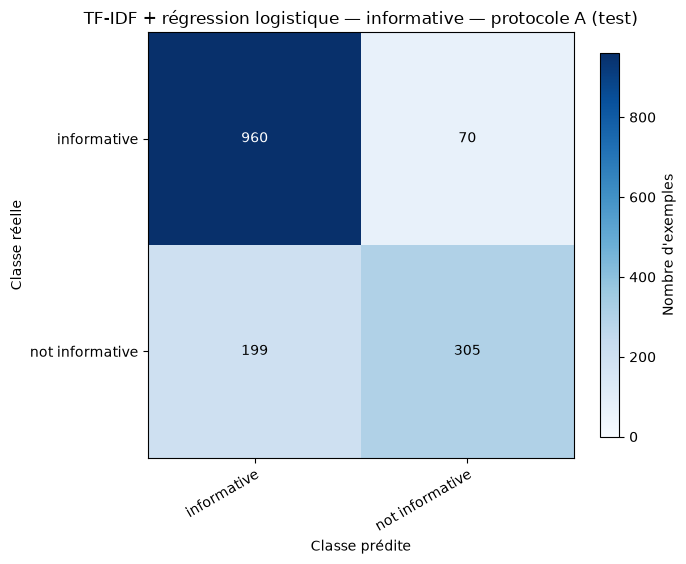

In [9]:
informative_test_metrics = evaluate_selected_test("informative")


### 7.2 Humanitarian — test du modèle retenu


Prédictions : results/predictions/humanitarian_tfidf_A_official.csv
Métriques : results/metrics/humanitarian_tfidf_A_official.json


,task,n_samples,f1_macro,f1_weighted,accuracy
0,humanitarian,955,0.634204,0.744188,0.740314


,precision,recall,f1-score,support
label,,,,
affected_individuals,0.375000,0.333333,0.352941,9
infrastructure_and_utility_damage,0.566667,0.629630,0.596491,81
rescue_volunteering_or_donation_effort,0.621118,0.793651,0.696864,126
other_relevant_information,0.672598,0.804255,0.732558,235
not_humanitarian,0.877108,0.722222,0.792165,504


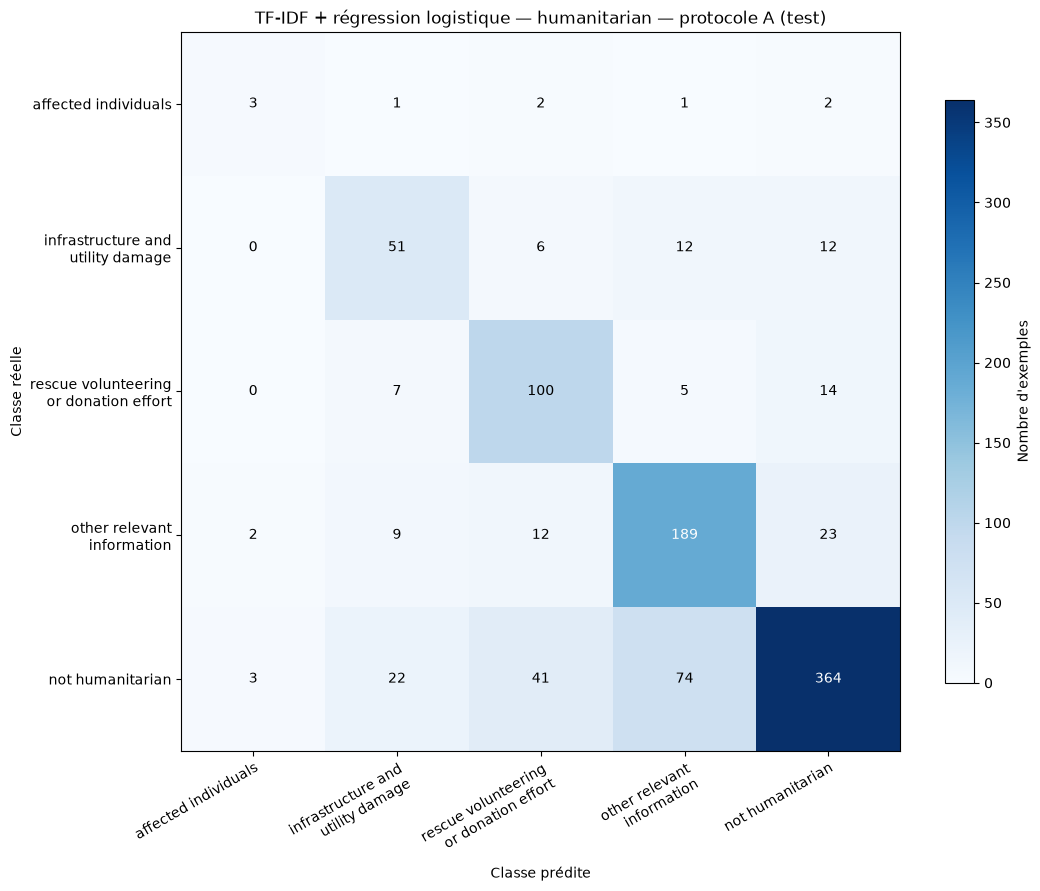

In [10]:
humanitarian_test_metrics = evaluate_selected_test("humanitarian")


## 8. Synthèse reproductible

Le tableau final est relu depuis les JSON d'évaluation. Il distingue le score de
sélection dev du score test et inclut l'IC à 95 % du F1 macro.
La classe `affected_individuals` ne compte que **9 exemples test** : consulter ses
métriques par classe et interpréter le F1 macro avec prudence. Les IC sont ceux
du bootstrap commun ; ils ne mesurent pas la variabilité entre seeds.
Les scores de littérature du projet ne sont pas utilisés pour sélectionner `C`.
Aucune modification d'hyperparamètre n'est faite après observation du test.


In [11]:
summary_rows = []
for task in TASKS:
    metrics = json.loads(test_artifacts[task]['metrics'].read_text(encoding='utf-8'))
    interval = metrics['bootstrap']['intervals']['f1_macro']
    summary_rows.append(dict(task=task, model='tfidf', protocol='A', fold='official',
                             selected_C=selected[task]['C'], dev_f1_macro=selected[task]['dev_f1_macro'],
                             test_rows=metrics['n_samples'], f1_macro=metrics['f1_macro'],
                             f1_macro_ci95_lower=interval['lower'], f1_macro_ci95_upper=interval['upper'],
                             f1_weighted=metrics['f1_weighted'], accuracy=metrics['accuracy']))
summary = pd.DataFrame(summary_rows)
summary.to_csv(TABLE_DIR / 'tfidf_A_summary.csv', index=False)
display(summary)
for relative, expected in input_hashes.items():
    assert hashlib.sha256((REPO_ROOT / relative).read_bytes()).hexdigest() == expected, relative
assert test_started == set(TASKS)
print('Terminé : deux sélections dev, une évaluation test par tâche, fichiers sources et splits inchangés.')
print('Tables : results/tables/ | Prédictions : results/predictions/ | Métriques : results/metrics/ | Figures : figures/')


,task,model,protocol,fold,selected_C,dev_f1_macro,test_rows,f1_macro,f1_macro_ci95_lower,f1_macro_ci95_upper,f1_weighted,accuracy
0,informative,tfidf,A,official,1.0,0.770613,1534,0.785542,0.762753,0.806893,0.816941,0.824641
1,humanitarian,tfidf,A,official,100.0,0.622650,955,0.634204,0.565392,0.694341,0.744188,0.740314


Terminé : deux sélections dev, une évaluation test par tâche, fichiers sources et splits inchangés.
Tables : results/tables/ | Prédictions : results/predictions/ | Métriques : results/metrics/ | Figures : figures/


## 9. Fichiers produits et relance

- `results/tables/{task}_tfidf_A_validation.csv` : résultats dev pour chaque `C`.
- `results/tables/tfidf_A_dev_metrics.json` : métriques dev complètes issues de l'évaluateur commun.
- `results/tables/tfidf_A_run_config.json` : configuration, sélection, versions et empreintes des entrées.
- `results/predictions/{task}_tfidf_A_official.csv` : identifiants, vérité, prédiction et probabilités.
- `results/metrics/{task}_tfidf_A_official.json` : métriques test, par classe, matrice et IC bootstrap.
- `results/tables/{task}_tfidf_A_official_{per_class,confusion_matrix}.csv` : exports depuis les JSON test.
- `figures/{task}_tfidf_A_official_confusion_matrix.png` : matrices de confusion annotées.
- `results/tables/tfidf_A_summary.csv` : synthèse des deux tâches.

Relancer avec un kernel vierge et **Run All**. Les sorties sont réécrites aux mêmes
emplacements. Une réexécution complète est une nouvelle reproduction de l'expérience,
pas une nouvelle recherche d'hyperparamètres sur test. Aucun checkpoint n'est sauvegardé.
